# 03 · Extensión experimental: ¿qué pasa si la muestra es más pequeña? (Etapa 7)

**Una sola condición modificada: el tamaño de la muestra.** Todo lo demás se mantiene igual que en el notebook 02: mismos datos reales, mismas 34 variables, mismos algoritmos y misma validación cruzada de 5 particiones. Sólo cambia *n*.

**Por qué esta condición.** El artículo trabaja con 52.039 anuncios. Un trabajo de grado basado en *web scraping* de dos ciudades puede terminar con unos pocos miles de anuncios por ciudad. La pregunta es si la ventaja de LightGBM sobre OLS/SAR se mantiene cuando hay pocos datos.

**Diseño.** n ∈ {52.039, 26.000, 10.000, 5.000, 2.000, 1.000}; submuestras aleatorias sin reemplazo, 3 repeticiones (semillas distintas) para n < 52.039. Para SAR, el número de vecinos *k* de la matriz W se escala con n (k = 700·n/52.039, mínimo 8) para conservar el mismo radio espacial. Además de las métricas del artículo se calculan la mediana de la razón, el COD y el PRD (complemento para el OE4 del trabajo de grado).

**Hipótesis.** Con menos datos el error de todos los modelos sube, pero el de LightGBM sube más rápido que el de OLS/SAR (los árboles necesitan datos para aprender las no linealidades), de modo que la brecha a favor de LightGBM se reduce.

In [1]:
import sys, time
sys.path.insert(0, "..")
import numpy as np, pandas as pd
from IPython.display import Image, display
from src import config as C, analisis as A, figuras as F
from src.datos_reales import cargar_reales
pd.set_option("display.width", 180)
C.DIR_RESULTADOS.mkdir(exist_ok=True)
df = cargar_reales()

TAMANOS = [52_039, 26_000, 10_000, 5_000, 2_000, 1_000]
REPETICIONES = 3
RECALCULAR = False   # True = repetir todo el experimento (~25 min); False = reutilizar results/ si ya existe
ruta_detalle = C.DIR_RESULTADOS / "extension_tamano_muestra_detalle.csv"

if ruta_detalle.exists() and not RECALCULAR:
    ext = pd.read_csv(ruta_detalle)
    print("Se reutilizan los resultados guardados en", ruta_detalle.name)
else:
    filas, t0 = [], time.time()
    for n in TAMANOS:
        for s in ([0] if n == len(df) else range(1, REPETICIONES + 1)):
            filas += A.evaluar_tamano(df, n, semilla=s)
        print(f"n = {n:>6,}  listo ({time.time() - t0:.0f} s)")
    ext = pd.DataFrame(filas)
    ext.to_csv(ruta_detalle, index=False)

d:\academico\maestria_analitica_aplicada\semestre 2\Machine Learning 2\proyecto\proyecto_ajustes\proyecto_ml_final_datos_reales\proyecto_ml_final\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Se reutilizan los resultados guardados en extension_tamano_muestra_detalle.csv


### Resultados (media de las repeticiones)

In [2]:
resumen = ext.groupby(["n", "modelo"])[["MAPE", "MdAPE", "MAE", "RMSE", "R2", "mediana_razon", "COD", "PRD"]].mean().round(3)
resumen.to_csv(C.DIR_RESULTADOS / "extension_tamano_muestra_resumen.csv")
resumen.reset_index().pivot(index="n", columns="modelo", values=["MAPE", "R2", "COD", "PRD"]).sort_index(ascending=False).round(3)

MAPE                       R2                    COD                      PRD              
modelo LightGBM     OLS     SAR LightGBM    OLS    SAR LightGBM     OLS     SAR LightGBM    OLS    SAR
n                                                                                                     
52039    10.848  21.846  22.203    0.947  0.683  0.637   10.823  21.518  21.898    1.022  1.054  1.046
26000    11.917  21.877  22.270    0.938  0.678  0.627   11.890  21.560  21.964    1.026  1.053  1.045
10000    13.276  21.875  22.233    0.926  0.676  0.627   13.260  21.543  21.917    1.031  1.054  1.046
5000     14.457  21.890  22.146    0.916  0.675  0.639   14.438  21.511  21.894    1.036  1.053  1.046
2000     15.411  22.073  22.310    0.903  0.641  0.622   15.426  21.722  22.063    1.040  1.050  1.044
1000     16.674  22.805  23.143    0.886  0.596  0.562   16.708  22.576  22.911    1.043  1.050  1.046

In [3]:
p = ext.groupby(["n", "modelo"]).MAPE.mean().unstack()
ventaja = pd.DataFrame({"MAPE LightGBM": p["LightGBM"], "MAPE mejor econométrico": p[["OLS", "SAR"]].min(axis=1)})
ventaja["reducción de error por usar LightGBM (%)"] = 100 * (1 - ventaja["MAPE LightGBM"] / ventaja["MAPE mejor econométrico"])
ventaja = ventaja.sort_index(ascending=False)
ventaja.to_csv(C.DIR_RESULTADOS / "extension_ventaja_lightgbm.csv")
ventaja.round(2)

,MAPE LightGBM,MAPE mejor econométrico,reducción de error por usar LightGBM (%)
n,,,
52039,10.85,21.85,50.34
26000,11.92,21.88,45.53
10000,13.28,21.88,39.31
5000,14.46,21.89,33.95
2000,15.41,22.07,30.18
1000,16.67,22.80,26.88


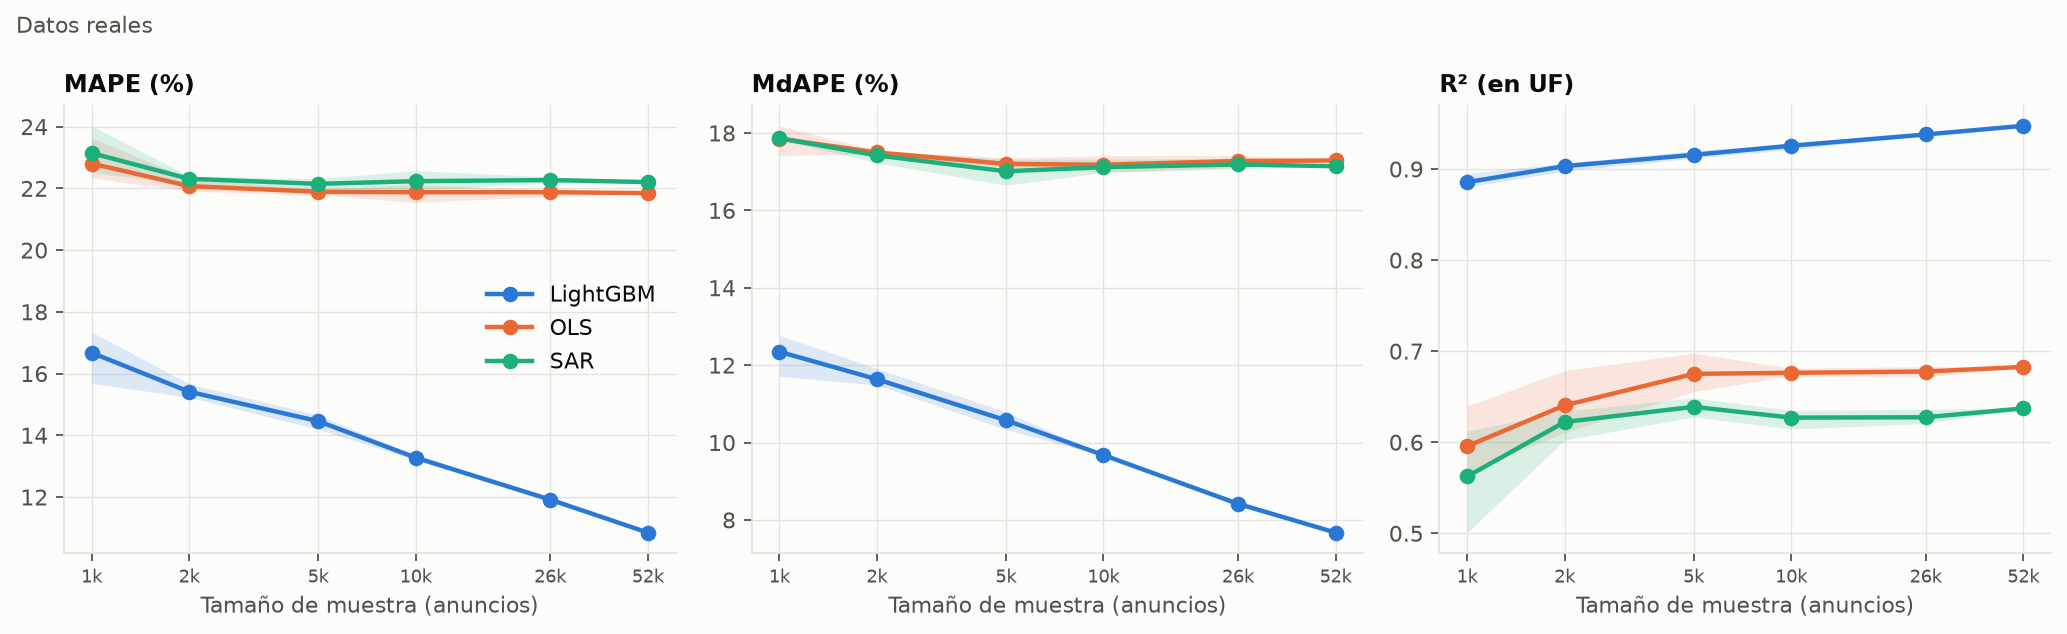

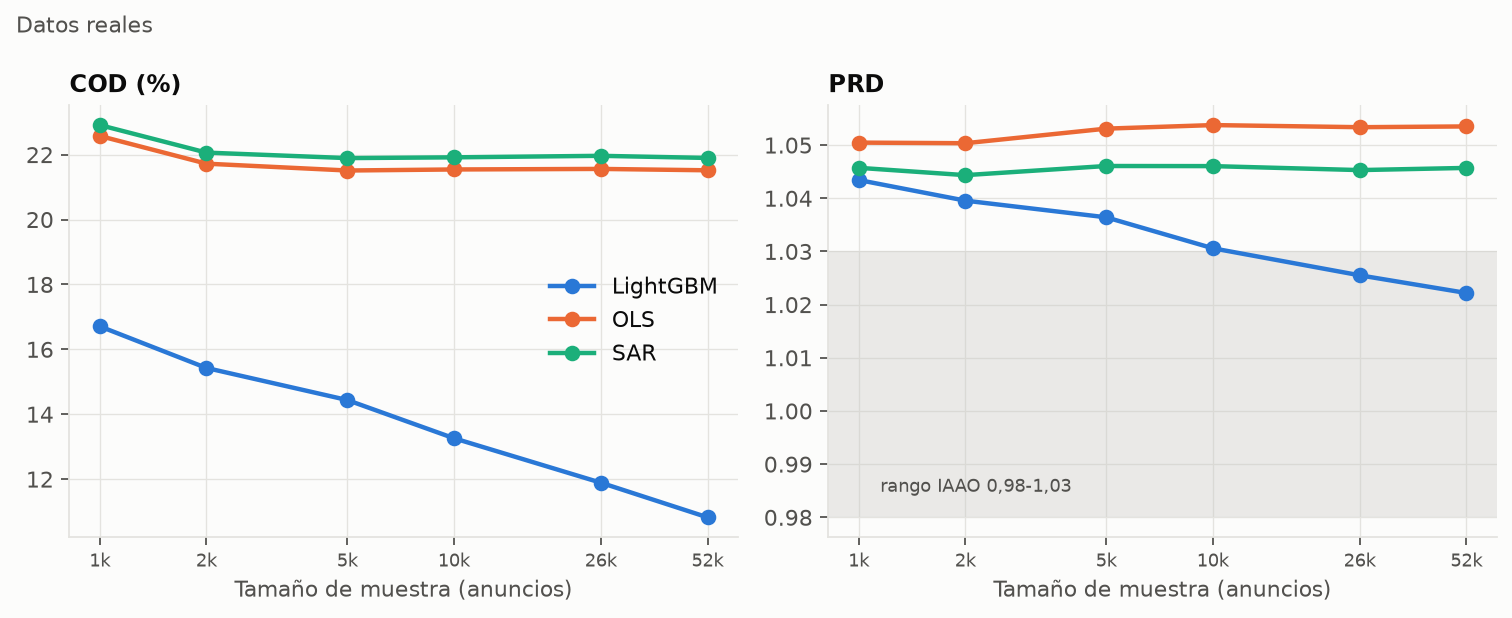

In [4]:
display(Image(str(F.fig_extension(ext, "real"))))
display(Image(str(F.fig_extension_razon(ext, "real"))))

## Etapa 8 · Conclusiones
1. **La conclusión central del artículo se sostiene con sus datos:** LightGBM comete cerca de la mitad del error de OLS y SAR (MAPE 10,8 % frente a 21,9 % y 22,2 %; artículo: 10,0 %, 21,1 % y 20,9 %). El I de Moran de ln(precio), el R² y rho de la Tabla 8, los signos de los 33 coeficientes SAR y el cambio de signo del efecto de los colegios entre OLS y SAR se reproducen (notebook 02).
2. **Lo que no se reprodujo igual:** con la forma reducida el SAR sale peor que OLS en validación cruzada (el artículo reporta lo contrario; con los precios de los vecinos sí queda mejor), y las 10 variables de fotos casi no mejoran el error. Una parte probable de la diferencia es usar GBDT con 400 árboles en vez de DART con 8.000.
3. **Extensión:** al reducir la muestra de 52.039 a 1.000 anuncios, el MAPE de LightGBM sube de 10,9 % a 16,7 % y el del mejor modelo econométrico casi no cambia (21,9 % → 22,8 %); LightGBM sigue siendo mejor, pero su ventaja baja de 50 % a 27 %. El PRD de OLS y SAR queda alrededor de 1,05, sobre el rango 0,98–1,03 (referencia no verificada aquí); el de LightGBM baja de 1,043 a 1,022 al aumentar la muestra.
4. **Para el trabajo de grado:** con pocos anuncios por ciudad conviene esperar errores mayores que los del artículo y comparar siempre contra OLS/SAR; la validación debe ser espacial (OE3) y las métricas de razón (OE4) se calculan además de las del artículo. Lo que queda pendiente: validación espacial por bloques y correr el modo DART completo.